# Signals in spatial and branched cables

How does a local voltage change become a traveling signal through a branch?

Fall 2024.


# How does a signal travel through a branch?
Predict the ordering of start, junction and tip arrivals. State what “arrival” means before running. The geometry and stimulus are synthetic.

{'Start': 2.188703484087372, 'Junction': 3.7993682561504034, 'Upper tip': 4.692250707365337, 'Lower tip': 4.912751908805438}


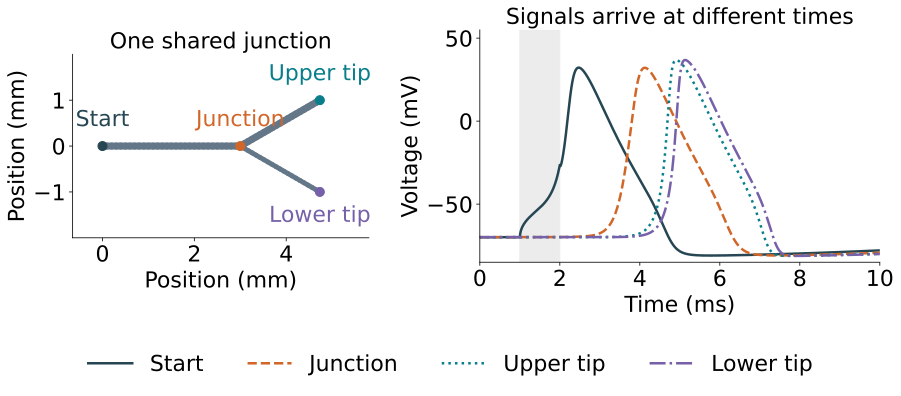

In [1]:
from demo import run
from cable import simulate, arrivals
from IPython.display import SVG, display
import numpy as np
result = run()
print(dict(zip(result['probe_labels'], result['probe_arrival_ms'])))
display(SVG(filename='branched-probes.svg'))

Interpret: use the same zero-crossing event at the junction and upper tip. Explain why the delay from stimulus onset would answer another question.

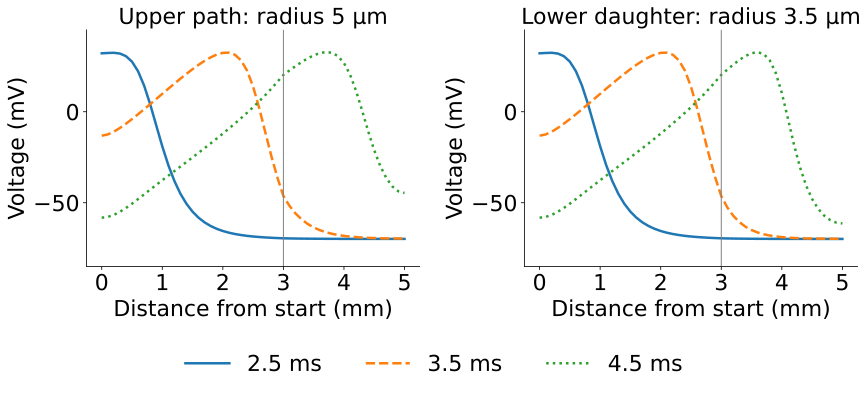

Upper daughter average speed (mm/ms): 2.239936508191674
Full step budget error (µA ms): 2.270048298641525e-17


In [2]:
display(SVG(filename='traveling-profiles.svg'))
arrival = result['probe_arrival_ms']
print('Upper daughter average speed (mm/ms):', 2/(arrival[2]-arrival[1]))
print('Full step budget error (µA ms):', result['max_step_budget_error_uA_ms'])

Modify: make the daughter radii equal while retaining the same physical lengths, total current and initial state. Predict whether the two tip traces should differ. Then run a coarser exploratory mesh and report its resolution.

In [3]:
symmetric = simulate(intervals=12, daughter_ratio=1, dt=.01, end=7)
tips = symmetric['geometry']['tips']
gap = np.max(abs(symmetric['voltage_mV'][:, tips[0]] - symmetric['voltage_mV'][:, tips[1]]))
print('Equal-daughter maximum voltage gap (mV):', gap)
assert gap < 1e-10
print('Arrival times (ms):', arrivals(symmetric['time_ms'], symmetric['voltage_mV'][:, tips]))

Equal-daughter maximum voltage gap (mV):

 0.0
Arrival times (ms): [4.762419693279569, 4.762419693279569]


Conclude: state one checked numerical property and one biological claim that is not established. Describe the further time/space or experimental comparison needed to assess that claim.